# Quadrature-Channel FSM Mach-Zehnder Simulation

This notebook simulates the vertical and horizontal photodiode channels of a quadrature Mach-Zehnder interferometer with one fast-steering mirror. Edit the parameter cells below to explore beam width, divergence, wavelength, FSM-to-combiner distance, detector imbalance, and FSM jitter.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from fsm_mzi_sim import (
    BeamConfig,
    DetectorConfig,
    FSMJitterConfig,
    FSMTone,
    InterferometerConfig,
    PolarizationConfig,
    ReferenceMirrorTapConfig,
    FSMMotion,
    animate_example_evolution,
    estimate_opd_from_quadrature,
    plot_beam_cross_section,
    plot_diagnostics,
    plot_quadrature,
    simulate_reference_mirror_tap,
    simulate_fsm_motion,
    simulate_quadrature,
)

plt.rcParams.update({"figure.dpi": 120})

## Configure The Bench

Distances are meters, angles are radians, and the beam radius is the 1/e^2 intensity radius. The waveplate controls below use degrees for readability, then convert to radians for the simulation.

In [15]:
# Real-life beam setup.
# If "1 mm beam size" means diameter, use radius = 0.5e-3.
# If it means 1/e^2 radius, use radius = 1.0e-3.
output_beam_radius_m = 0.5e-3
distance_output_aperture_to_fsm_m = 0.75
beam_divergence_half_angle_rad = 0.35e-3

beam = BeamConfig(
    wavelength_m=635e-9,
    radius_at_output_aperture_m=output_beam_radius_m,
    distance_output_aperture_to_fsm_m=distance_output_aperture_to_fsm_m,
    divergence_half_angle_rad=beam_divergence_half_angle_rad,
)

interferometer = InterferometerConfig(
    distance_fsm_to_combiner_m=0.35,
    fsm_incidence_angle_rad=np.deg2rad(45),
    input_power_w=1.0,
    baseline_visibility=0.96,
    nominal_phase_rad=0.25,
    quadrature_phase_rad=np.pi / 2,
    fsm_vertical_pivot_offset_m=0.8e-3,
    fsm_horizontal_pivot_offset_m=0.8e-3,
    piston_shear_axis="horizontal",
    include_piston_opd=True,
    include_piston_shear=True,
    include_angular_path_length=True,
)

# Polarization optics. Angles are waveplate fast-axis angles measured from vertical.
# Positive angle means rotating the fast axis from vertical toward horizontal.
# Looking along the beam propagation direction, compare this to the sign on your mount.
# A HWP fast axis at 22.5 deg rotates vertical input light to 45 deg diagonal.
reference_hwp_nominal_fast_axis_angle_deg = 22.5
fsm_qwp_nominal_fast_axis_angle_deg = 45.0
reference_hwp_angle_error_deg = 0.0
fsm_qwp_angle_error_deg = 0.0
reference_hwp_fast_axis_angle_deg = reference_hwp_nominal_fast_axis_angle_deg + reference_hwp_angle_error_deg
fsm_qwp_fast_axis_angle_deg = fsm_qwp_nominal_fast_axis_angle_deg + fsm_qwp_angle_error_deg

nominal_polarization = PolarizationConfig(
    input_linear_angle_rad=np.deg2rad(0.0),
    reference_hwp_fast_axis_angle_rad=np.deg2rad(reference_hwp_nominal_fast_axis_angle_deg),
    reference_hwp_retardance_rad=np.pi,
    fsm_qwp_fast_axis_angle_rad=np.deg2rad(fsm_qwp_nominal_fast_axis_angle_deg),
    fsm_qwp_retardance_rad=np.pi / 2,
    reference_arm_power_fraction=0.5,
    fsm_arm_power_fraction=0.5,
)

polarization = PolarizationConfig(
    input_linear_angle_rad=np.deg2rad(0.0),
    reference_hwp_fast_axis_angle_rad=np.deg2rad(reference_hwp_fast_axis_angle_deg),
    reference_hwp_retardance_rad=np.pi,
    fsm_qwp_fast_axis_angle_rad=np.deg2rad(fsm_qwp_fast_axis_angle_deg),
    fsm_qwp_retardance_rad=np.pi / 2,
    reference_arm_power_fraction=0.5,
    fsm_arm_power_fraction=0.5,
)

detector = DetectorConfig(
    vertical_gain=1.0,
    horizontal_gain=0.96,
    vertical_offset_w=0.0,
    horizontal_offset_w=0.015,
    vertical_contrast=1.0,
    horizontal_contrast=1.0,
    read_noise_std_w=0.003,
    relative_intensity_noise_std=0.0,
)

{
    "radius_at_output_aperture_mm": beam.radius_at_output_aperture_m * 1e3,
    "radius_at_fsm_mm": beam.radius_at_fsm_effective_m * 1e3,
    "radius_at_combiner_mm": float(beam.radius_at(interferometer.distance_fsm_to_combiner_m)) * 1e3,
    "reference_hwp_fast_axis_angle_deg": reference_hwp_fast_axis_angle_deg,
    "fsm_qwp_fast_axis_angle_deg": fsm_qwp_fast_axis_angle_deg,
}

{'radius_at_output_aperture_mm': 0.5,
 'radius_at_fsm_mm': 0.5647178499038259,
 'radius_at_combiner_mm': 0.6310507111159926}

## Generate FSM Motion

The synthetic generator includes random FSM steering and piston motion plus optional sinusoidal vibration components.

- `vertical_steering_*` is the mirror rotation that sends the reflected beam up/down out of the optical-table plane.
- `horizontal_steering_*` is the mirror rotation that sends the reflected beam left/right within the optical-table plane.
- Both steering values are mirror angles. The reflected beam deflects by twice the mirror angle.
- `piston_*` is physical mirror-normal surface motion. It changes optical path length and, for non-normal incidence, laterally shifts the reflected beam.
- `fsm_incidence_angle_rad` controls the piston coupling. At 45 degrees, `piston` contributes about `sqrt(2) * piston` to OPD and about `sqrt(2) * piston` to lateral beam shear.
- `piston_shear_axis="horizontal"` matches a vertical FSM mirror whose normal lies in the optical-table plane, so piston beam walk stays in-plane.

To use measured data instead, build `FSMMotion(time_s, vertical_steering_angle_rad, horizontal_steering_angle_rad, piston_m)` from your arrays.

In [16]:
jitter = FSMJitterConfig(
    sample_rate_hz=50_000,
    duration_s=0.04,
    vertical_steering_rms_rad=0.7e-6,
    horizontal_steering_rms_rad=0.45e-6,
    piston_rms_m=35e-9,
    correlation_time_s=80e-6,
    tones=(
        FSMTone(
            frequency_hz=650,
            vertical_steering_amplitude_rad=1.8e-6,
            piston_amplitude_m=45e-9,
        ),
        FSMTone(
            frequency_hz=2100,
            horizontal_steering_amplitude_rad=0.75e-6,
            piston_phase_rad=1.2,
        ),
    ),
    seed=11,
)

motion = simulate_fsm_motion(jitter)
result = simulate_quadrature(motion, beam, interferometer, detector, polarization=polarization, noise_seed=23)

result.to_dataframe().head()

,time_s,vertical_w,horizontal_w,phase_rad,wrapped_phase_rad,visibility,gaussian_overlap,opd_m,mirror_vertical_steering_angle_rad,mirror_horizontal_steering_angle_rad,...,steering_vertical_shear_m,steering_horizontal_shear_m,piston_induced_shear_m,piston_induced_opd_m,reference_mirror_displacement_m,reference_mirror_opd_m,reference_mirror_vertical_shear_m,reference_mirror_horizontal_shear_m,vertical_shear_m,horizontal_shear_m
0,0.00000,0.977220,0.560950,-0.136105,-0.136105,0.960000,1.000000,-3.902114e-08,2.393494e-08,-1.464880e-07,...,1.675446e-08,-1.025416e-07,-3.882508e-08,-3.882508e-08,0.0,0.0,0.0,0.0,1.675446e-08,-1.413666e-07
1,0.00002,0.980356,0.479304,0.034780,0.034780,0.959986,0.999986,-2.175130e-08,7.625551e-07,3.596068e-07,...,5.337886e-07,2.517248e-07,-2.354726e-08,-2.354726e-08,0.0,0.0,0.0,0.0,5.337886e-07,2.281775e-07
2,0.00004,0.971394,0.413031,0.187533,0.187533,0.959967,0.999965,-6.314292e-09,1.310011e-06,1.320911e-07,...,9.170077e-07,9.246375e-08,-8.622869e-09,-8.622869e-09,0.0,0.0,0.0,0.0,9.170077e-07,8.384088e-08
3,0.00006,0.952732,0.355866,0.291871,0.291871,0.959978,0.999977,4.230837e-09,1.004854e-06,3.904370e-07,...,7.033978e-07,2.733059e-07,1.997558e-09,1.997558e-09,0.0,0.0,0.0,0.0,7.033978e-07,2.753034e-07
4,0.00008,0.959425,0.357284,0.302941,0.302941,0.959975,0.999974,5.349461e-09,8.893585e-07,7.226176e-07,...,6.225510e-07,5.058323e-07,2.769380e-09,2.769380e-09,0.0,0.0,0.0,0.0,6.225510e-07,5.086017e-07


## Beam Walk At The Combiner

This treats the recombining beamsplitter plane as a stationary quadcell-like cross-section. The plotted point is the relative beam-center displacement between the two arms. Horizontal displacement is in the optical-table plane; vertical displacement is out of the plane.

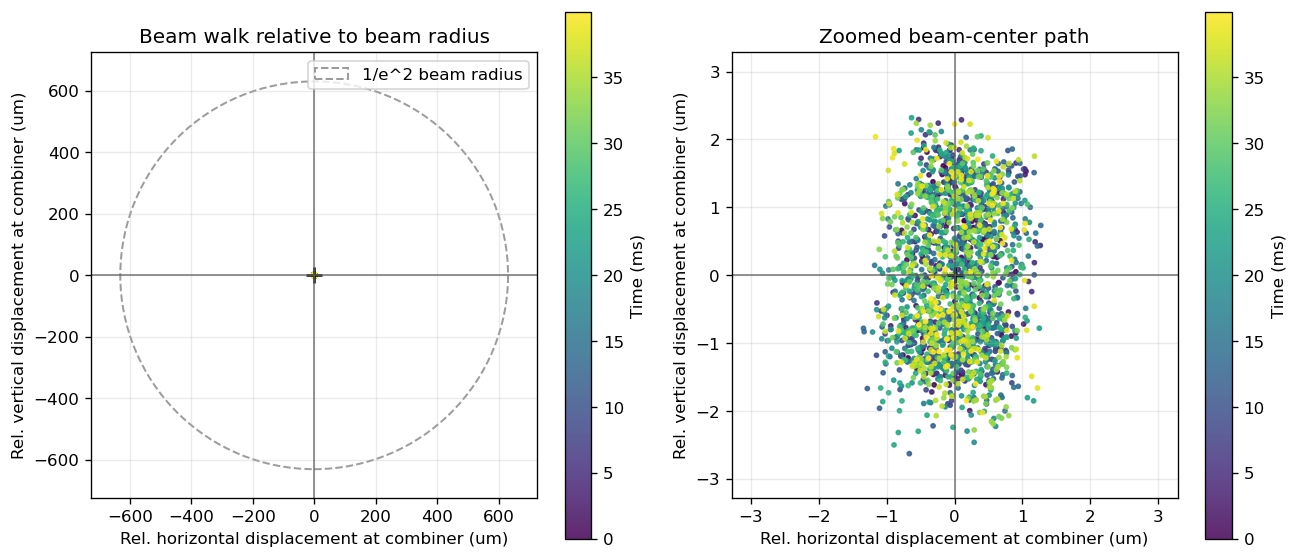

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

plot_beam_cross_section(
    result,
    ax=axes[0],
    color_by="time",
    point_size=6,
    show_beam_radius=True,
    zoom="beam",
)
axes[0].set_title("Beam walk relative to beam radius")

plot_beam_cross_section(
    result,
    ax=axes[1],
    color_by="time",
    point_size=6,
    show_beam_radius=False,
    zoom="path",
)
axes[1].set_title("Zoomed beam-center path")

fig.tight_layout()

## Tap The Other Mirror To Sweep OPD

This is the simulation version of tapping the non-FSM mirror to make the quadrature circle. By default, the tap displacement points toward the combiner, so it mainly changes OPD. The two direction angles can be made nonzero later if you want the tap to also add small beam walk/misalignment.

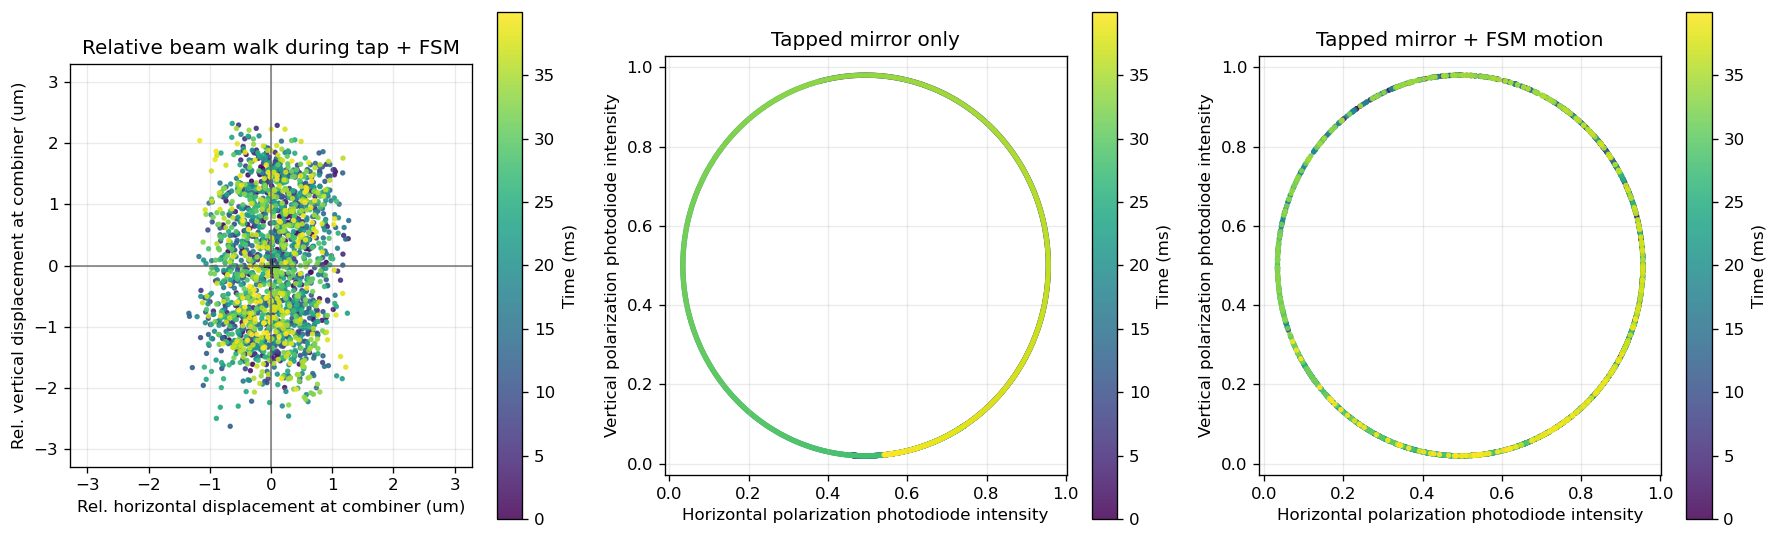

In [13]:
reference_tap = simulate_reference_mirror_tap(
    ReferenceMirrorTapConfig(
        sample_rate_hz=jitter.sample_rate_hz,
        duration_s=jitter.duration_s,
        amplitude_m=350e-9,
        frequency_hz=30,
        horizontal_direction_angle_rad=0.0,
        vertical_direction_angle_rad=0.0,
        opd_coupling=1.0,
        positive_toward_combiner_shortens_opd=True,
    )
)

zero_fsm_motion = FSMMotion(
    time_s=motion.time_s,
    vertical_steering_angle_rad=np.zeros_like(motion.time_s),
    horizontal_steering_angle_rad=np.zeros_like(motion.time_s),
    piston_m=np.zeros_like(motion.time_s),
)

tap_detector = DetectorConfig(
    vertical_gain=detector.vertical_gain,
    horizontal_gain=detector.horizontal_gain,
    vertical_offset_w=detector.vertical_offset_w,
    horizontal_offset_w=detector.horizontal_offset_w,
    vertical_contrast=detector.vertical_contrast,
    horizontal_contrast=detector.horizontal_contrast,
    read_noise_std_w=0.0,
    relative_intensity_noise_std=0.0,
)

tap_only_result = simulate_quadrature(
    zero_fsm_motion,
    beam,
    interferometer,
    tap_detector,
    reference_mirror_motion=reference_tap,
    polarization=polarization,
)
nominal_tap_only_result = simulate_quadrature(
    zero_fsm_motion,
    beam,
    interferometer,
    tap_detector,
    reference_mirror_motion=reference_tap,
    polarization=nominal_polarization,
)
tap_plus_fsm_result = simulate_quadrature(
    motion,
    beam,
    interferometer,
    tap_detector,
    reference_mirror_motion=reference_tap,
    polarization=polarization,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
plot_beam_cross_section(
    tap_plus_fsm_result,
    ax=axes[0],
    color_by="time",
    point_size=5,
    show_beam_radius=False,
    zoom="path",
)
axes[0].set_title("Relative beam walk during tap + FSM")
plot_quadrature(tap_only_result, ax=axes[1], color_by="time", point_size=5)
axes[1].set_title("Tapped mirror only")
plot_quadrature(tap_plus_fsm_result, ax=axes[2], color_by="time", point_size=5)
axes[2].set_title("Tapped mirror + FSM motion")
fig.tight_layout()

## Simple Deterministic FSM Motion Examples

These examples remove random jitter and drive the FSM with clean sinusoidal motion while the tapped reference mirror sweeps OPD. The actuation amplitude is intentionally larger than the random jitter above so the beam path is easy to see.

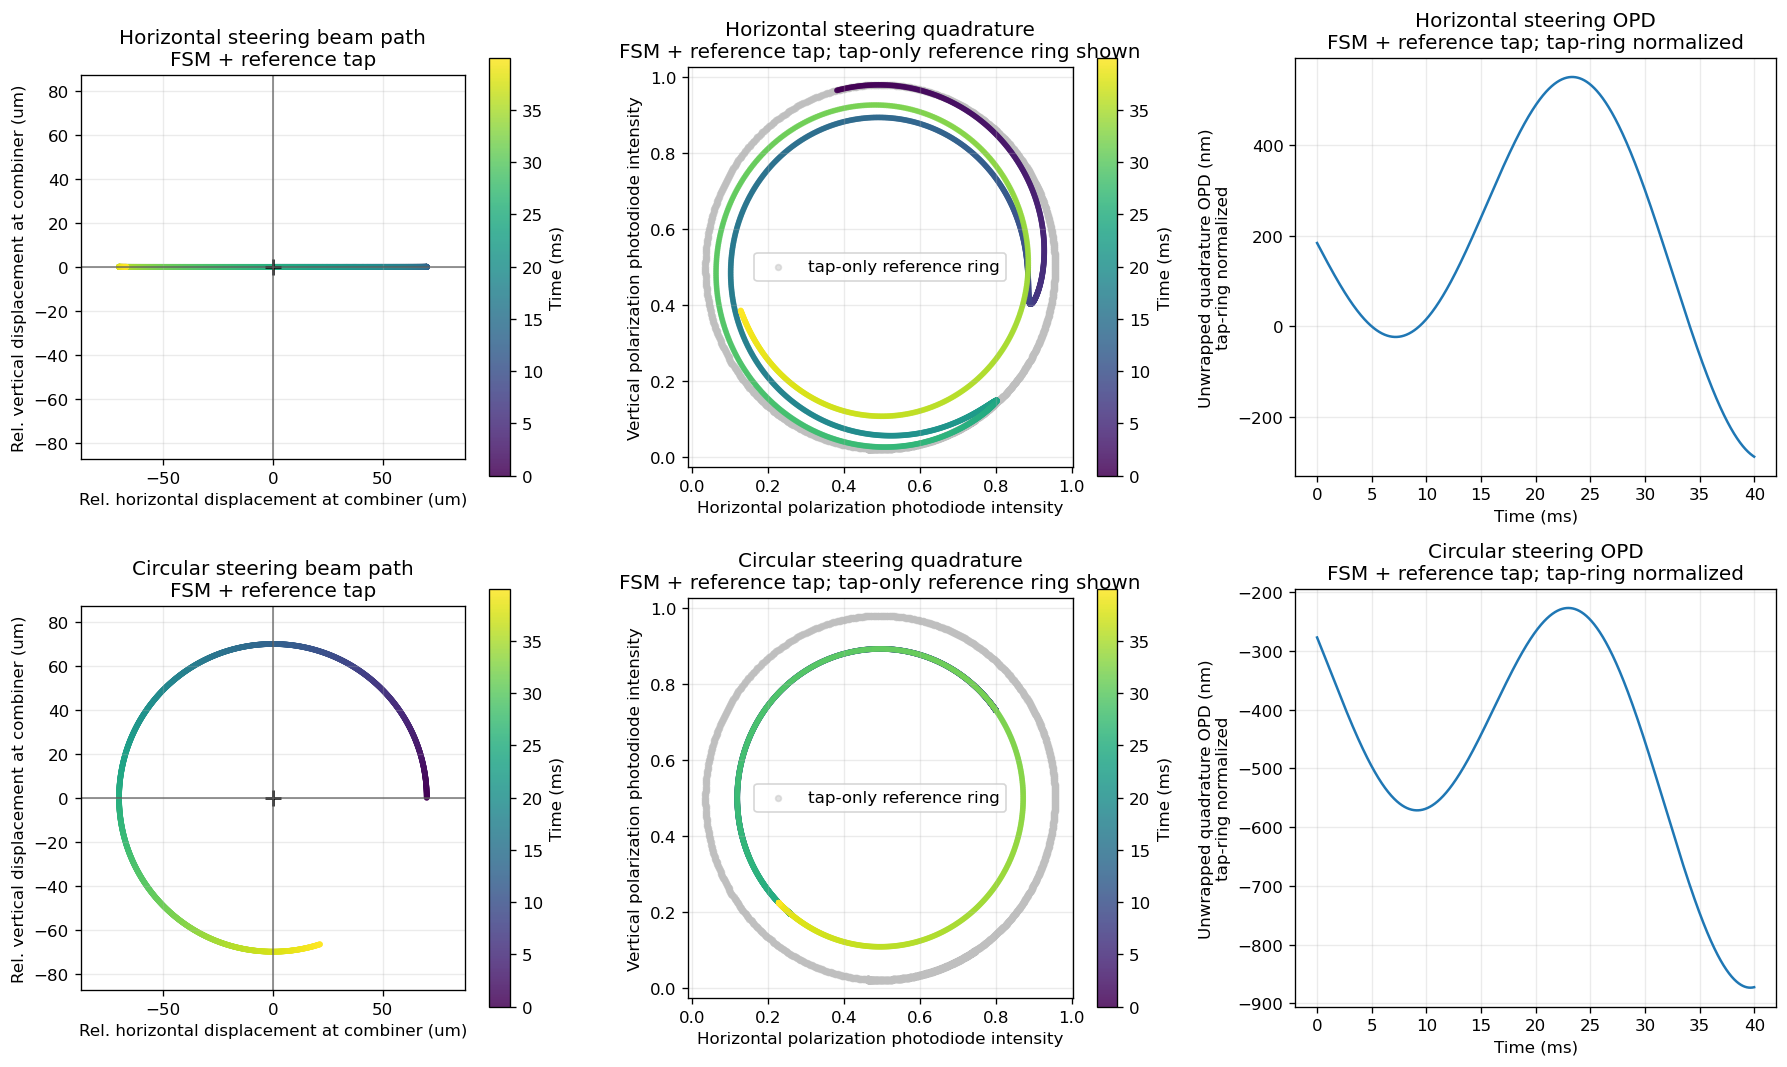

In [19]:
demo_sample_rate_hz = jitter.sample_rate_hz
demo_duration_s = jitter.duration_s
demo_frequency_hz = 20
demo_angle_amplitude_rad = 100e-6
use_reference_tap_for_examples = True
show_tap_only_reference_ring = True
show_nominal_waveplate_reference_ring = True

example_reference_tap = reference_tap if use_reference_tap_for_examples else None
example_motion_label = "FSM + reference tap" if use_reference_tap_for_examples else "FSM only"
example_overlay_parts = []
if show_tap_only_reference_ring:
    example_overlay_parts.append("current tap ring shown")
if show_nominal_waveplate_reference_ring:
    example_overlay_parts.append("nominal ring shown")
example_overlay_label = "; ".join(example_overlay_parts) if example_overlay_parts else "no reference rings"
example_opd_label = "tap-ring normalized" if show_tap_only_reference_ring else "self-normalized"

demo_time_s = reference_tap.time_s
demo_phase = 2 * np.pi * demo_frequency_hz * demo_time_s
zero_motion = np.zeros_like(demo_time_s)
deterministic_detector = DetectorConfig(
    vertical_gain=detector.vertical_gain,
    horizontal_gain=detector.horizontal_gain,
    vertical_offset_w=detector.vertical_offset_w,
    horizontal_offset_w=detector.horizontal_offset_w,
    vertical_contrast=detector.vertical_contrast,
    horizontal_contrast=detector.horizontal_contrast,
    read_noise_std_w=0.0,
    relative_intensity_noise_std=0.0,
)


horizontal_back_and_forth = FSMMotion(
    time_s=demo_time_s,
    vertical_steering_angle_rad=zero_motion,
    horizontal_steering_angle_rad=demo_angle_amplitude_rad * np.sin(demo_phase),
    piston_m=zero_motion,
)

circular_steering = FSMMotion(
    time_s=demo_time_s,
    vertical_steering_angle_rad=demo_angle_amplitude_rad * np.sin(demo_phase),
    horizontal_steering_angle_rad=demo_angle_amplitude_rad * np.cos(demo_phase),
    piston_m=zero_motion,
)

horizontal_result = simulate_quadrature(
    horizontal_back_and_forth,
    beam,
    interferometer,
    deterministic_detector,
    reference_mirror_motion=example_reference_tap,
    polarization=polarization,
    noise_seed=None,
)
circular_result = simulate_quadrature(
    circular_steering,
    beam,
    interferometer,
    deterministic_detector,
    reference_mirror_motion=example_reference_tap,
    polarization=polarization,
    noise_seed=None,
)

opd_reference = tap_only_result if show_tap_only_reference_ring else None
_, horizontal_opd_m = estimate_opd_from_quadrature(
    horizontal_result,
    beam.wavelength_m,
    reference_result=opd_reference,
)
_, circular_opd_m = estimate_opd_from_quadrature(
    circular_result,
    beam.wavelength_m,
    reference_result=opd_reference,
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

plot_beam_cross_section(
    horizontal_result,
    ax=axes[0, 0],
    color_by="time",
    point_size=6,
    show_beam_radius=False,
    zoom="path",
)
axes[0, 0].set_title(f"Horizontal steering beam path\n{example_motion_label}")
if show_nominal_waveplate_reference_ring:
    axes[0, 1].plot(
        nominal_tap_only_result.horizontal_w,
        nominal_tap_only_result.vertical_w,
        color="0.35",
        linewidth=1.5,
        alpha=0.75,
        label="nominal zero-error ring",
    )
if show_tap_only_reference_ring:
    axes[0, 1].scatter(
        tap_only_result.horizontal_w,
        tap_only_result.vertical_w,
        s=12,
        color="0.72",
        alpha=0.45,
        label="current waveplate tap ring",
    )
plot_quadrature(horizontal_result, ax=axes[0, 1], color_by="time", point_size=6)
axes[0, 1].set_title(f"Horizontal steering quadrature\n{example_motion_label}; {example_overlay_label}")
if show_tap_only_reference_ring or show_nominal_waveplate_reference_ring:
    axes[0, 1].legend(loc="best")
axes[0, 2].plot(demo_time_s * 1e3, horizontal_opd_m * 1e9)
axes[0, 2].set_title(f"Horizontal steering OPD\n{example_motion_label}; {example_opd_label}")
axes[0, 2].set_xlabel("Time (ms)")
axes[0, 2].set_ylabel(f"Unwrapped quadrature OPD (nm)\n{example_opd_label}")
axes[0, 2].grid(True, alpha=0.25)

plot_beam_cross_section(
    circular_result,
    ax=axes[1, 0],
    color_by="time",
    point_size=6,
    show_beam_radius=False,
    zoom="path",
)
axes[1, 0].set_title(f"Circular steering beam path\n{example_motion_label}")
if show_nominal_waveplate_reference_ring:
    axes[1, 1].plot(
        nominal_tap_only_result.horizontal_w,
        nominal_tap_only_result.vertical_w,
        color="0.35",
        linewidth=1.5,
        alpha=0.75,
        label="nominal zero-error ring",
    )
if show_tap_only_reference_ring:
    axes[1, 1].scatter(
        tap_only_result.horizontal_w,
        tap_only_result.vertical_w,
        s=12,
        color="0.72",
        alpha=0.45,
        label="current waveplate tap ring",
    )
plot_quadrature(circular_result, ax=axes[1, 1], color_by="time", point_size=6)
axes[1, 1].set_title(f"Circular steering quadrature\n{example_motion_label}; {example_overlay_label}")
if show_tap_only_reference_ring or show_nominal_waveplate_reference_ring:
    axes[1, 1].legend(loc="best")
axes[1, 2].plot(demo_time_s * 1e3, circular_opd_m * 1e9)
axes[1, 2].set_title(f"Circular steering OPD\n{example_motion_label}; {example_opd_label}")
axes[1, 2].set_xlabel("Time (ms)")
axes[1, 2].set_ylabel(f"Unwrapped quadrature OPD (nm)\n{example_opd_label}")
axes[1, 2].grid(True, alpha=0.25)

fig.tight_layout()

## Animated FSM Motion Examples

These GIFs animate the same deterministic examples over time. They are saved in `outputs/` so you can replay or compare them later.

In [ ]:
output_dir = repo_root / "outputs"
output_dir.mkdir(exist_ok=True)

animation_reference = tap_only_result if show_tap_only_reference_ring else None
animation_nominal_reference = nominal_tap_only_result if show_nominal_waveplate_reference_ring else None
horizontal_gif = output_dir / "horizontal_steering_example.gif"
circular_gif = output_dir / "circular_steering_example.gif"

animate_example_evolution(
    horizontal_result,
    beam,
    horizontal_gif,
    reference_result=animation_reference,
    nominal_reference_result=animation_nominal_reference,
    title=f"Horizontal steering ({example_motion_label}; {example_overlay_label})",
    fps=20,
    max_frames=160,
)
animate_example_evolution(
    circular_result,
    beam,
    circular_gif,
    reference_result=animation_reference,
    nominal_reference_result=animation_nominal_reference,
    title=f"Circular steering ({example_motion_label}; {example_overlay_label})",
    fps=20,
    max_frames=160,
)

display(Image(filename=str(horizontal_gif)))
display(Image(filename=str(circular_gif)))

## Quadrature Plot

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_quadrature(result, ax=ax, color_by="time", point_size=6)
fig.tight_layout()

## Diagnostics

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(9, 8.5), sharex=True)
plot_diagnostics(result, axes=axes)
fig.tight_layout()

## Sweep FSM Angular Jitter

This sweep keeps piston jitter constant while increasing vertical steering jitter. The circle collapses or thickens as Gaussian overlap varies across the run.

In [ ]:
vertical_steering_rms_values = [0.1e-6, 0.8e-6, 2.0e-6, 4.0e-6]

fig, axes = plt.subplots(
    1,
    len(vertical_steering_rms_values),
    figsize=(14, 3.6),
    sharex=True,
    sharey=True,
)

for ax, vertical_steering_rms in zip(axes, vertical_steering_rms_values):
    sweep_motion = simulate_fsm_motion(
        FSMJitterConfig(
            sample_rate_hz=50_000,
            duration_s=0.03,
            vertical_steering_rms_rad=vertical_steering_rms,
            horizontal_steering_rms_rad=0.6 * vertical_steering_rms,
            piston_rms_m=35e-9,
            correlation_time_s=80e-6,
            seed=12,
        )
    )
    sweep_result = simulate_quadrature(
        sweep_motion,
        beam,
        interferometer,
        detector,
        polarization=polarization,
        noise_seed=24,
    )
    plot_quadrature(sweep_result, ax=ax, color_by=None, point_size=4, alpha=0.45)
    ax.set_title(f"vertical steering RMS = {vertical_steering_rms * 1e6:.1f} urad")

fig.tight_layout()

## Sweep Physical Piston Beam Walk

This isolates physical piston-induced beam shear by turning off random steering. With a sub-mm beam, nanometer piston mostly changes phase; contrast loss from beam walk becomes visible only when piston motion is large compared with the beam radius.

In [ ]:
piston_rms_values = [35e-9, 1e-6, 10e-6, 100e-6]

fig, axes = plt.subplots(
    1,
    len(piston_rms_values),
    figsize=(14, 3.6),
    sharex=True,
    sharey=True,
)

for ax, piston_rms in zip(axes, piston_rms_values):
    piston_motion = simulate_fsm_motion(
        FSMJitterConfig(
            sample_rate_hz=50_000,
            duration_s=0.03,
            vertical_steering_rms_rad=0.0,
            horizontal_steering_rms_rad=0.0,
            piston_rms_m=piston_rms,
            correlation_time_s=80e-6,
            seed=13,
        )
    )
    piston_result = simulate_quadrature(
        piston_motion,
        beam,
        interferometer,
        detector,
        polarization=polarization,
        noise_seed=25,
    )
    plot_quadrature(piston_result, ax=ax, color_by=None, point_size=4, alpha=0.45)
    ax.set_title(f"piston RMS = {piston_rms * 1e9:.0f} nm")

fig.tight_layout()

## Using Measured FSM Data

If your controller logs vertical steering, horizontal steering, and piston-equivalent motion, replace the synthetic generator with your arrays.

In [ ]:
# Example shape for measured data:
# time_s = measured_time
# vertical_steering_angle_rad = measured_out_of_plane_angle
# horizontal_steering_angle_rad = measured_in_plane_angle
# piston_m = measured_physical_mirror_normal_motion
# If you measured OPD instead, use: piston_m = measured_opd / (2 * np.cos(interferometer.fsm_incidence_angle_rad))
# measured_motion = FSMMotion(time_s, vertical_steering_angle_rad, horizontal_steering_angle_rad, piston_m)
# measured_result = simulate_quadrature(measured_motion, beam, interferometer, detector, polarization=polarization)
# plot_quadrature(measured_result)